In [103]:
import sys
print(sys.version)
print('pandas version', pd.__version__)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
pandas version 2.2.3


In [ ]:
## ASK questions about the data
## The winter season is November 1, 2024 - March 31, 2025
## On how many days was snowmaking possible?
## Assuming trails open at 9AM and close at 4:30PM
## Snowmaking crews work for 16.5 hours
## To make snow, temperature must be 27 degrees Farenheit and below
## Humidity must be low between 30% and 60%

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [37]:
## This dataset provided by the NCEI or National Centers for Environmental Information has a record of daily snowfall totals.

In [ ]:
## As provided, this table has a title, I'm going to include a parameter header=1 to begin the index on the second row.

In [170]:
df = pd.read_csv("C:/Users/Spencer Woo/Downloads/data(9).csv", header=1)

In [171]:
df

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
0,1975-02-01,NaN,40.0,31.0,0.46,0.0,0.0
1,1975-02-02,NaN,34.0,27.0,0.40,4.0,4.0
2,1975-02-03,NaN,36.0,19.0,0.00,0.0,NaN
3,1975-02-04,NaN,30.0,14.0,0.00,0.0,NaN
4,1975-02-05,NaN,45.0,17.0,1.18,15.0,17.0
...,...,...,...,...,...,...,...
18571,2025-12-06,NaN,27.0,18.0,0.01,0.5,3.0
18572,2025-12-07,NaN,30.0,17.0,0.00,0.0,NaN
18573,2025-12-08,NaN,35.0,19.0,0.01,0.2,3.0
18574,2025-12-09,NaN,26.0,14.0,0.30,2.0,5.0


In [172]:
df.shape

(18576, 7)

In [173]:
df.head()

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
0,1975-02-01,NaN,40.0,31.0,0.46,0.0,0.0
1,1975-02-02,NaN,34.0,27.0,0.40,4.0,4.0
2,1975-02-03,NaN,36.0,19.0,0.00,0.0,NaN
3,1975-02-04,NaN,30.0,14.0,0.00,0.0,NaN
4,1975-02-05,NaN,45.0,17.0,1.18,15.0,17.0


In [181]:
df.dtypes

Date                          object
TAVG (Degrees Fahrenheit)    float64
TMAX (Degrees Fahrenheit)    float64
TMIN (Degrees Fahrenheit)    float64
PRCP (Inches)                float64
SNOW (Inches)                float64
SNWD (Inches)                float64
dtype: object

<Axes: >

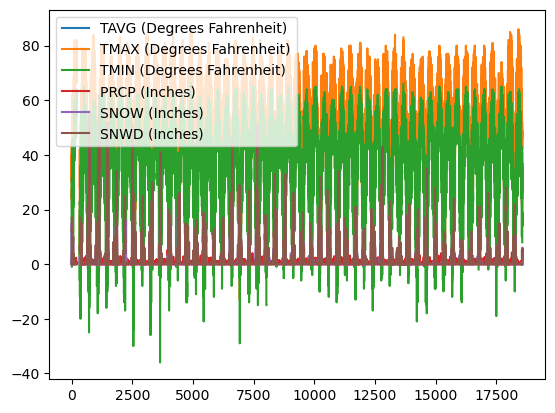

In [61]:
df.plot()

In [ ]:
## Notice the table has two separate columns for snowfall and snow depth
## Remember, we are looking for snowfall.

In [174]:
df.columns

Index(['Date', 'TAVG (Degrees Fahrenheit)', 'TMAX (Degrees Fahrenheit)',
       'TMIN (Degrees Fahrenheit)', 'PRCP (Inches)', 'SNOW (Inches)',
       'SNWD (Inches)'],
      dtype='object')

In [ ]:
## Copy and paste the results of df.columns into double brackets to take a subset of the data

In [175]:
df[['Date','SNOW (Inches)']]

,Date,SNOW (Inches)
0,1975-02-01,0.0
1,1975-02-02,4.0
2,1975-02-03,0.0
3,1975-02-04,0.0
4,1975-02-05,15.0
...,...,...
18571,2025-12-06,0.5
18572,2025-12-07,0.0
18573,2025-12-08,0.2
18574,2025-12-09,2.0


In [66]:
df.isna().sum()

Date                             0
TAVG (Degrees Fahrenheit)    18576
TMAX (Degrees Fahrenheit)      692
TMIN (Degrees Fahrenheit)      830
PRCP (Inches)                  589
SNOW (Inches)                  680
SNWD (Inches)                  765
dtype: int64

In [ ]:
## This dataset is very large and spans many winter seasons.
## I only need the 2024-2025 winter season.
## I'm going to find the rows where our season begins and ends using loc

In [67]:
df.loc[df['Date']=='2024-11-01']

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.0,0.0,0.0


In [ ]:
## End of season is March 30 or index 18351

In [69]:
df.loc[df['Date']=='2025-04-30']

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18351,2025-04-30,NaN,75.0,44.0,0.2,0.0,0.0


In [ ]:
## and then filter only the relevant data from the set using the indices as a range

In [107]:
df.iloc[18171:18351]

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18346,2025-04-25,NaN,69.0,42.0,0.00,0.0,0.0
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0


In [ ]:
## The query method can do this in one declaration

In [178]:
df.query("Date >= '2024-11-01' and Date <= '2025-04-30'")

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0
18350,2025-04-29,NaN,69.0,29.0,0.00,0.0,0.0


In [ ]:
## Save this query as a subset of the original dataset without modifying the original

In [179]:
ss = df.query("Date >= '2024-11-01' and Date <= '2025-04-30'")

In [180]:
ss[['Date', 'SNOW (Inches)']]

,Date,SNOW (Inches)
18171,2024-11-01,0.0
18172,2024-11-02,0.0
18173,2024-11-03,0.0
18174,2024-11-04,0.0
18175,2024-11-05,0.0
...,...,...
18347,2025-04-26,0.0
18348,2025-04-27,0.0
18349,2025-04-28,0.0
18350,2025-04-29,0.0


<Axes: xlabel='Date'>

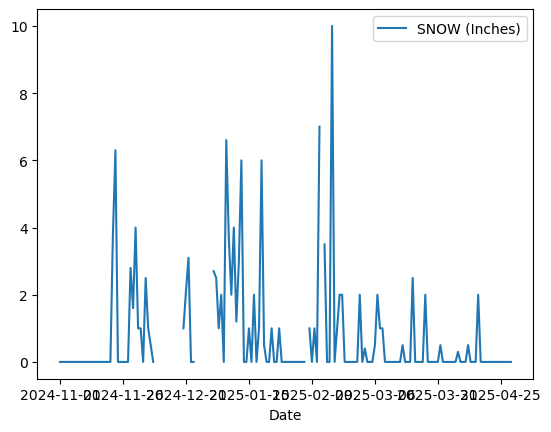

In [101]:
ss.plot('Date', kind='line')

In [ ]:
## what if we found another dataset and cross referenced to fill in the blanks?
## this is why it is important to explore the data for nulls before you graph.

## this graph is difficult to read, I think it would be better to separate this graph into facets by month.

In [ ]:
## There are 17 rows missing the daily snowfall total.

In [130]:
ss['SNOW (Inches)'].isna().sum()

np.int64(17)

In [104]:
df[['TAVG (Degrees Fahrenheit)', 'SNOW (Inches)']].agg(['mean', 'min', 'max'])

,TAVG (Degrees Fahrenheit),SNOW (Inches)
mean,NaN,0.403174
min,NaN,0.000000
max,NaN,26.000000


In [132]:
del ss